In [14]:
from scipy.stats import norm
from scipy.integrate import trapezoid as trapz

import matplotlib.pyplot as plt

import numpy as np

# `tanh`

In [86]:
x = np.linspace(0, 100, 1000)

def distance_score_specz(galaxy_distance, gw_dist_mean, gw_dist_std, nsigma=2, smoothing=2):
    if not isinstance(galaxy_distance, np.ndarray):
        galaxy_distance = np.asarray(galaxy_distance)
        
    score = np.zeros(len(galaxy_distance))

    # for specz's higher than the gw distance mean
    score[galaxy_distance < gw_dist_mean] = np.tanh(
       1/smoothing * ((galaxy_distance[galaxy_distance < gw_dist_mean] + nsigma*gw_dist_std) - gw_dist_mean)
    )
    
    # for specz's lower than the gw distance mean
    score[galaxy_distance >= gw_dist_mean] = np.tanh(
        1/smoothing * ((gw_dist_mean + nsigma*gw_dist_std) - galaxy_distance[galaxy_distance >= gw_dist_mean])
    )

    return score

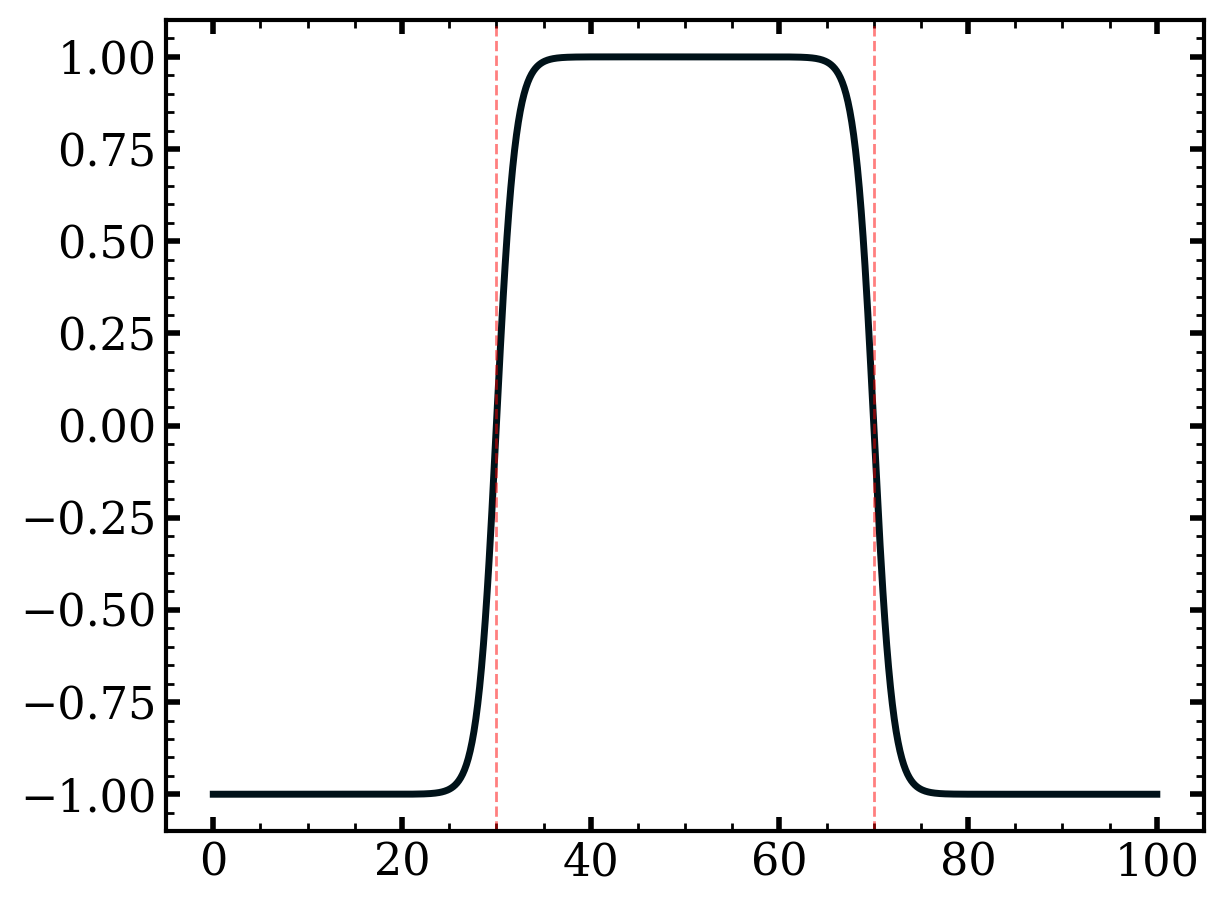

In [87]:
plt.plot(x, distance_score_specz(x, 50, 10))
plt.axvline(30, color="red", alpha=0.5, lw=1, linestyle="--")
plt.axvline(70, color="red", alpha=0.5, lw=1, linestyle="--")

# Tophat with Gaussian Tail

In [115]:
def tophat_gaussian_tail(galaxy_specz_distance, gw_mean, gw_std, nsigma=2):
    lower_bound = gw_mean - nsigma*gw_std
    upper_bound = gw_mean + nsigma*gw_std

    gw = norm.pdf(x, gw_mean, gw_std)
    score = gw/np.max(gw[(galaxy_specz_distance < lower_bound)+(galaxy_specz_distance > upper_bound)]) * np.ones(len(x))
    score[(galaxy_specz_distance >= lower_bound) * (galaxy_specz_distance <= upper_bound)] = 1 # top hat between these bounds

    return score

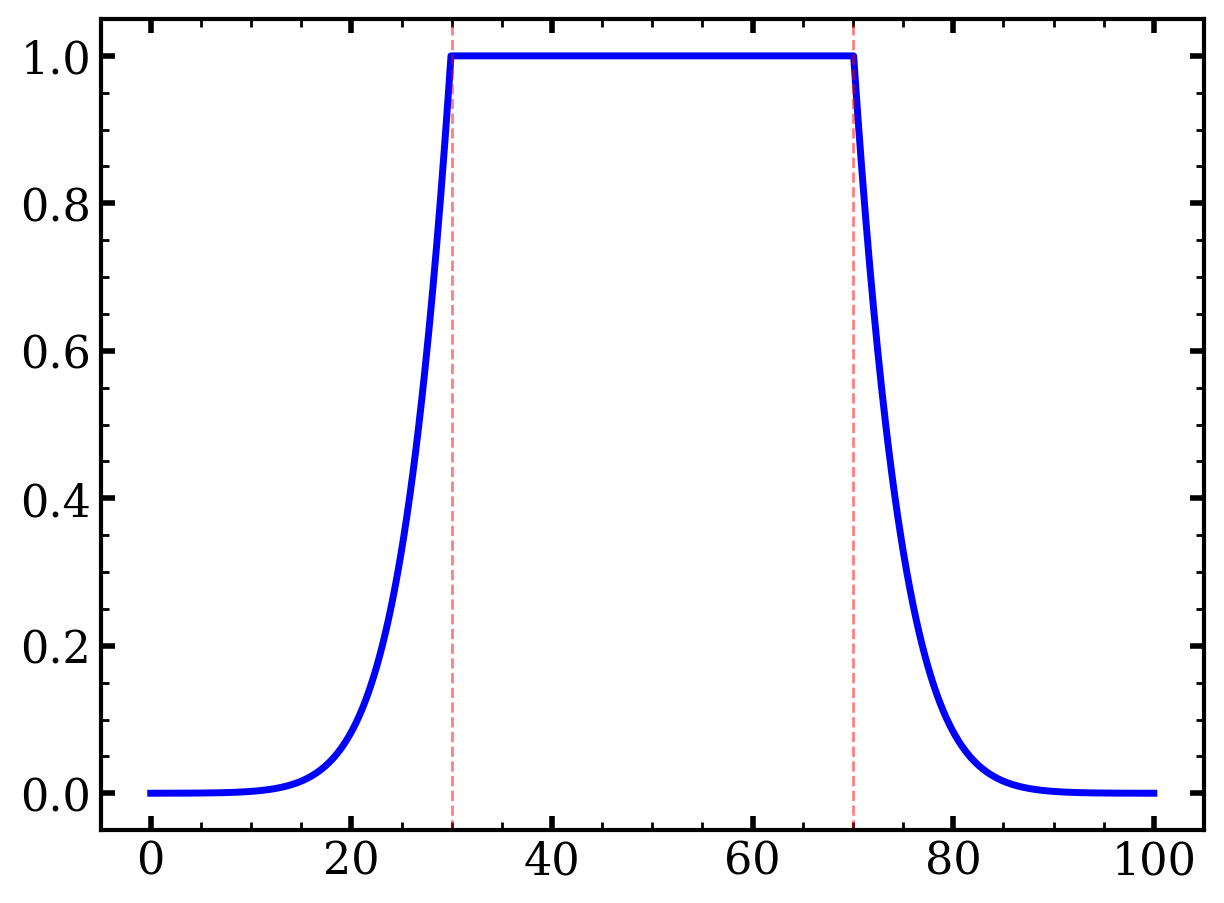

In [116]:
gw_mean = 50
gw_std = 10
x = np.linspace(0, 100, 1000)

plt.plot(x, tophat_gaussian_tail(x, gw_mean, gw_std), color="blue", label="gaussian+tophat")
plt.axvline(30, color="red", alpha=0.5, lw=1, linestyle="--")
plt.axvline(70, color="red", alpha=0.5, lw=1, linestyle="--")


# top-hat convolved with a gaussian kernel

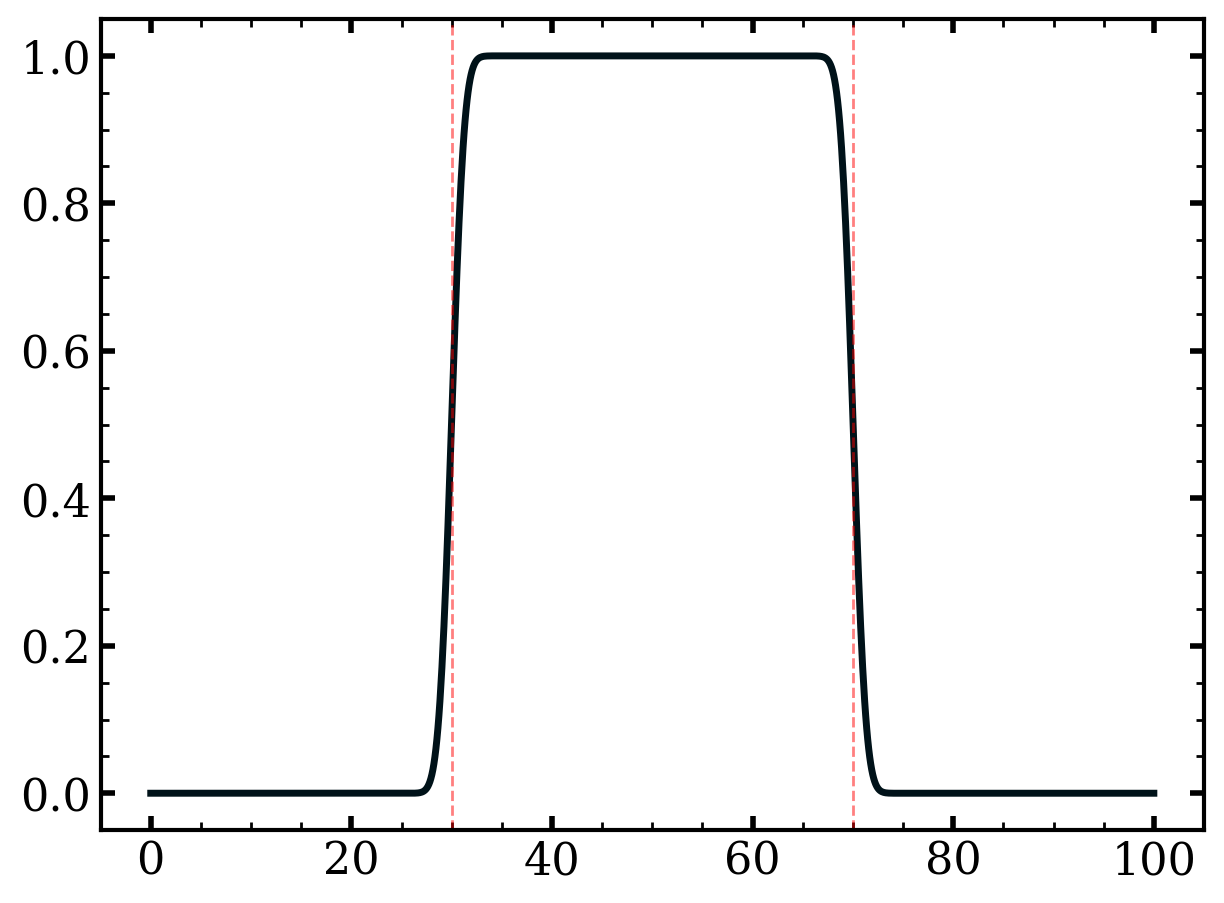

In [137]:
import numpy as np
from astropy.modeling.models import Lorentz1D
from astropy.convolution import convolve, Gaussian1DKernel, Box1DKernel

def smooth_tophat_score(x, gw_mean, gw_std, nsigma=2):
    lower_bound = gw_mean - nsigma*gw_std
    upper_bound = gw_mean + nsigma*gw_std
    
    gaussian_kernel = Gaussian1DKernel(gw_std)
    
    tophat_score = np.zeros(len(x))
    tophat_score[(x > lower_bound) * (x < upper_bound)] = 1

    return convolve(tophat_score, gaussian_kernel)

gw_mean = 50
gw_std = 10
x = np.linspace(0, 100, 1000)

plt.plot(x, smooth_tophat_score(x, gw_mean, gw_std))
plt.axvline(30, color="red", alpha=0.5, lw=1, linestyle="--")
plt.axvline(70, color="red", alpha=0.5, lw=1, linestyle="--")

# Sigmoid Composition

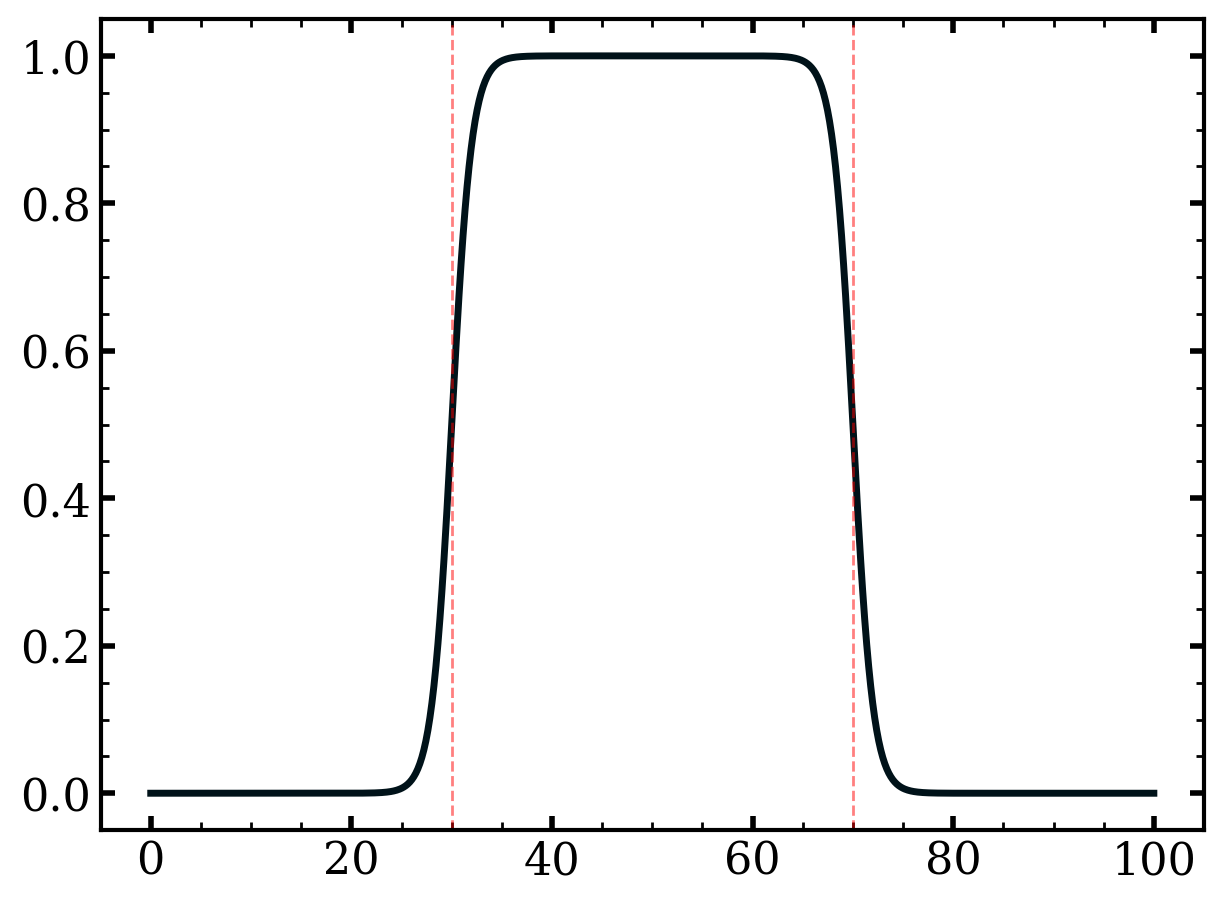

In [147]:


plt.plot(x, smooth_tophat(x, gw_mean-2*gw_std, gw_mean+2*gw_std, k=1))
plt.axvline(30, color="red", alpha=0.5, lw=1, linestyle="--")
plt.axvline(70, color="red", alpha=0.5, lw=1, linestyle="--")